# Speech emotion monitoring — training on Google Colab

UCCD3094 Assignment 2. This notebook is deliberately thin: it copies in the project code and
calls the scripts. All real logic lives in `src/`, so it can be reviewed properly rather than
buried in notebook cells.

## Before running

**Runtime → Change runtime type → T4 GPU.** Nothing else needs switching on; Colab has
internet by default and needs no phone verification.

## How files are arranged

Google Drive is slow with many small files, so we never keep 7,442 loose `.wav` files there.
Instead:

| What | Where it lives | Why |
| --- | --- | --- |
| `crema_d.zip` | Google Drive, one file | Survives disconnects; copying one big file is fast |
| Unzipped audio | `/content/`, rebuilt each session | Local disk, so training reads at full speed |
| Project code | Google Drive, copied to `/content/` | Same reason |
| Checkpoints and results | Google Drive | Colab disconnects without warning |

Sessions are cut off after inactivity and have a hard limit of roughly 12 hours, so the
training script saves a checkpoint after every epoch.

## 1. Check we actually got a GPU

In [5]:
import torch

print('torch', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU. Runtime -> Change runtime type -> T4 GPU, then run this again.')

torch 2.11.0+cu128
GPU available: True
GPU: Tesla T4


## 2. Connect Google Drive

A popup will ask you to sign in and grant access. Everything the project keeps permanently
lives under `MyDrive/uccd3094/`.

In [7]:
import os, shutil, sys, zipfile
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/uccd3094')
LOCAL = Path('/content/crema_d')
zipfile.ZipFile(DRIVE_ROOT / 'crema_d.zip').extractall(LOCAL) if not LOCAL.exists() else print('audio already unpacked')
AUDIO_DIR = (list(LOCAL.glob('**/AudioWAV')) or [next(LOCAL.glob('**/*.wav')).parent])[0]
print('audio dir:', AUDIO_DIR, '| wav files:', len(list(AUDIO_DIR.glob('*.wav'))))
CODE = Path('/content/project')
shutil.rmtree(CODE) if CODE.exists() else None
SRC = list(DRIVE_ROOT.glob('**/scripts/train.py'))[0].parents[1]
shutil.copytree(SRC, CODE)
os.chdir(CODE)
sys.path.insert(0, str(CODE)) if str(CODE) not in sys.path else None
print('code copied from:', SRC)
print('NEW audit script present:', (CODE / 'scripts' / 'audit_dataset.py').exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
audio already unpacked
audio dir: /content/crema_d/AudioWAV | wav files: 7442
code copied from: /content/drive/MyDrive/uccd3094/UCCD3094_Assignment2_upload
NEW audit script present: True


In [8]:
!python scripts/prepare_crema_d.py --audio-dir "{AUDIO_DIR}" --out /content/crema_d_manifest.csv
!python scripts/audit_dataset.py --audio-dir "{AUDIO_DIR}" --manifest /content/crema_d_manifest.csv --out "{DRIVE_ROOT}/results/dataset_audit.json"

found 7442 clips from 91 actors
split      clips  actors   emotion counts
train       5152      63   ANG:880 DIS:880 FEA:880 HAP:880 NEU:752 SAD:880
val         1142      14   ANG:195 DIS:195 FEA:195 HAP:195 NEU:167 SAD:195
test        1148      14   ANG:196 DIS:196 FEA:196 HAP:196 NEU:168 SAD:196

wrote /content/crema_d_manifest.csv
splits are speaker-independent (verified); seed = 1337
  ... 500/7442
  ... 1000/7442
  ... 1500/7442
  ... 2000/7442
  ... 2500/7442
  ... 3000/7442
  ... 3500/7442
  ... 4000/7442
  ... 4500/7442
  ... 5000/7442
  ... 5500/7442
  ... 6000/7442
  ... 6500/7442
  ... 7000/7442

audio dir : /content/crema_d/AudioWAV
files found: 7442
readable   : 7442

unparsable filenames: 0
unreadable files    : 0
silent files        : 1  (peak < 0.0001)
  1076_MTI_SAD_XX.wav
duplicate audio     : 3 group(s)
  2 identical: ['1006_TIE_HAP_XX.wav', '1006_TIE_NEU_XX.wav']
  2 identical: ['1013_WSI_DIS_XX.wav', '1013_WSI_SAD_XX.wav']
  2 identical: ['1017_IWW_ANG_XX.wav', '10

## 3. Get CREMA-D into Drive — one time only

You only do this once, ever. After that the zip sits in Drive and every future session just
copies it across.

**The easy way:** download the CREMA-D dataset in your browser from
<https://www.kaggle.com/datasets/ejlok1/cremad> (a plain Kaggle account is enough — no phone
verification needed to download), then upload the zip to `MyDrive/uccd3094/crema_d.zip`.

**The scripted way:** run the cell below. It needs a Kaggle API token — on Kaggle go to
Settings → API → Create New API Token, which downloads `kaggle.json`. Upload that when asked.

In [ ]:
ZIP_IN_DRIVE = DRIVE_ROOT / 'crema_d.zip'

if ZIP_IN_DRIVE.exists():
    print(f'Already in Drive: {ZIP_IN_DRIVE} ({ZIP_IN_DRIVE.stat().st_size / 1e6:.0f} MB)')
    print('Nothing to do. Skip to section 4.')
else:
    import os

    from google.colab import files

    print('Upload your kaggle.json when prompted...')
    files.upload()

    os.makedirs('/root/.config/kaggle', exist_ok=True)
    os.replace('kaggle.json', '/root/.config/kaggle/kaggle.json')
    os.chmod('/root/.config/kaggle/kaggle.json', 0o600)

    !pip install -q kaggle
    !kaggle datasets download -d ejlok1/cremad -p /content --quiet

    downloaded = next(Path('/content').glob('cremad*.zip'))
    print('copying to Drive, this takes a few minutes...')
    import shutil

    shutil.copy(downloaded, ZIP_IN_DRIVE)
    print('done:', ZIP_IN_DRIVE)

## 4. Unpack the audio locally — every session

Unzipping into Drive would take a very long time, because Drive is a network folder and this
is thousands of small files. Unzipping to `/content/` instead takes about a minute and
training reads it far faster.

In [12]:
import zipfile

LOCAL_DATA = Path('/content/crema_d')

if not LOCAL_DATA.exists():
    if not ZIP_IN_DRIVE.exists():
        raise SystemExit('crema_d.zip is not in Drive yet. Do section 3 first.')
    with zipfile.ZipFile(ZIP_IN_DRIVE) as archive:
        archive.extractall(LOCAL_DATA)

matches = list(LOCAL_DATA.glob('**/AudioWAV'))
if not matches:
    # Some copies of the dataset put the .wav files at the top level instead.
    matches = [p.parent for p in LOCAL_DATA.glob('**/*.wav')][:1]
if not matches:
    raise SystemExit(f'No .wav files found under {LOCAL_DATA}. Check the zip is CREMA-D.')

AUDIO_DIR = matches[0]
print('audio dir:', AUDIO_DIR)
print('wav files:', len(list(AUDIO_DIR.glob('*.wav'))), '(expect 7442)')

audio dir: /content/crema_d/AudioWAV
wav files: 7442 (expect 7442)


## 5. Get the project code

Upload the project folder to `MyDrive/uccd3094/UCCD3094_Assignment2_upload/` (build it with
`scripts/make_upload_bundle.py` rather than copying by hand). Leave out `.git/` and any
`__pycache__` folders.

> ⚠️ **Do not exclude anything called "data".** The project has a folder named `src/data/`
> that holds essential code. A blanket rule that skips folders named `data` will silently
> drop it, and the notebook will then fail with `No module named 'src.data'`. Only the
> top-level `data/` folder should be left out — and it is empty anyway.

The cell copies the project to local disk, because the training script needs to write files
and Drive is slow for that. It then checks that everything expected actually arrived.

In [ ]:
import os
import shutil
import sys

found = list(DRIVE_ROOT.glob('**/scripts/train.py'))
if not found:
    raise SystemExit(f'No project found under {DRIVE_ROOT}. Upload the project folder there.')

SOURCE_DIR = found[0].parents[1]  # .../scripts/train.py -> project root
CODE_DIR = Path('/content/project')

# Copy fresh every session, so an old version never lingers after you update Drive.
if CODE_DIR.exists():
    shutil.rmtree(CODE_DIR)
shutil.copytree(SOURCE_DIR, CODE_DIR)

os.chdir(CODE_DIR)
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# Fail loudly and specifically if the upload was incomplete. The usual cause is an
# exclusion rule for "data" that also removed src/data/.
REQUIRED = [
    'src/__init__.py',
    'src/data/__init__.py',
    'src/data/crema_d.py',
    'src/models/model.py',
    'src/train/loop.py',
    'src/evaluation/metrics.py',
    'scripts/train.py',
    'scripts/prepare_crema_d.py',
    'configs/crema_d_baseline.yaml',
]
missing = [name for name in REQUIRED if not (CODE_DIR / name).exists()]
if missing:
    raise SystemExit(
        'These files did not make it into Drive:\n  ' + '\n  '.join(missing) +
        '\n\nRe-upload the project folder. Do NOT exclude src/data/ -- only the empty '
        'top-level data/ folder should be left out.'
    )

print('copied from:', SOURCE_DIR)
print('working in :', Path.cwd())
print(f'checked {len(REQUIRED)} required files, all present')

## 6. Install what Colab does not ship

`torch` and `transformers` come preinstalled. `peft`, the LoRA library, does not.

In [13]:
!pip install -q peft
!pip uninstall -q -y torchao

29 checks, a few seconds, no dataset needed. If anything fails here, fix it before training.

In [ ]:
!python scripts/smoke_test.py

## 8. Build the manifest

Reads the filenames, derives the labels, and splits by actor so no speaker appears in more
than one split. Check the printed counts look sensible.

In [14]:
!python scripts/prepare_crema_d.py \
    --audio-dir "{AUDIO_DIR}" \
    --out /content/crema_d_manifest.csv

found 7442 clips from 91 actors
split      clips  actors   emotion counts
train       5152      63   ANG:880 DIS:880 FEA:880 HAP:880 NEU:752 SAD:880
val         1142      14   ANG:195 DIS:195 FEA:195 HAP:195 NEU:167 SAD:195
test        1148      14   ANG:196 DIS:196 FEA:196 HAP:196 NEU:168 SAD:196

wrote /content/crema_d_manifest.csv
splits are speaker-independent (verified); seed = 1337


### How many clips have no intensity label?

This decides whether the intensity head is worth training. If most clips are `XX`, leave
`heads.intensity` off in the config.

In [15]:
import collections
import os
import sys
from pathlib import Path

# Re-establish the working directory and import path here rather than relying on
# section 5 having run in this session. Restarting the Colab runtime clears both,
# and this cell is the first one that imports the project directly.
CODE_DIR = Path('/content/project')
if not CODE_DIR.exists():
    raise SystemExit('Run section 5 first -- the project has not been copied to /content yet.')
os.chdir(CODE_DIR)
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from src.data import read_manifest

clips = read_manifest('/content/crema_d_manifest.csv')
counts = collections.Counter(c.intensity for c in clips)
total = sum(counts.values())
for code, n in sorted(counts.items()):
    print(f'{code}: {n:5d}  ({100 * n / total:.1f}%)')

HI:   455  (6.1%)
LO:   455  (6.1%)
MD:   455  (6.1%)
XX:  6077  (81.7%)


## 9. Train

The config file holds every setting. `--override` changes one value without editing the file,
which is how the ablation runs are done.

The first run uses `--max-batches 5`, so it trains on five batches only. That proves the
whole path works end to end before committing real GPU time. Remove it for the real run.

In [ ]:
import os; print('manifest', os.path.exists('/content/crema_d_manifest.csv')); print('project', os.path.exists('/content/project/scripts/train.py')); print('audio', os.path.exists('/content/crema_d/AudioWAV')); print('drive', os.path.exists('/content/drive/MyDrive/uccd3094'))

### Fine-tuned run (LoRA) — `lora_e30`

Checkpoints and results go straight to Drive, so a disconnect costs you at most one epoch.

In [16]:
!python scripts/train.py --config configs/crema_d_baseline.yaml --run-id lora_e30 --override data.manifest=/content/crema_d_manifest.csv --override train.epochs=30 --checkpoint-dir "{DRIVE_ROOT}/checkpoints" --results-dir "{DRIVE_ROOT}/results"

Loading weights: 100% 248/248 [00:00<00:00, 14646.40it/s]
[lora_e30] 493,331 trainable of 94,875,267 (0.52%) on cuda
[lora_e30] mixed precision: on
epoch  train loss   val loss   val UAR     time  remaining
    1      1.7873     1.7768    0.2228     162s        78m  <- best
    2      1.7488     1.7100    0.3617     163s        76m  <- best
    3      1.6192     1.5528    0.3717     164s        73m  <- best
    4      1.4542     1.4363    0.4329     165s        71m  <- best
    5      1.3449     1.3950    0.4374     164s        68m  <- best
    6      1.2656     1.3309    0.4734     163s        65m  <- best
    7      1.2022     1.3141    0.4636     163s        63m
    8      1.1457     1.2481    0.4988     164s        60m  <- best
    9      1.1146     1.2023    0.5430     163s        57m  <- best
   10      1.0845     1.1489    0.5621     163s        54m  <- best
   11      1.0593     1.1131    0.5859     164s        52m  <- best
   12      1.0384     1.1194    0.5713     164s       

### Linear-probe baseline (frozen backbone) — `frozen_probe`

Same model, same manifest, but the backbone is frozen: only the classification head and
layer-pooling weights train. This is the reference point for "did fine-tuning actually
help?" — compare its unweighted average recall against `lora_e30` above.

In [ ]:
!python scripts/train.py \
    --config configs/crema_d_baseline.yaml \
    --run-id frozen_probe \
    --override model.finetune_strategy=frozen \
    --override data.manifest=/content/crema_d_manifest.csv \
    --override train.epochs=30 \
    --checkpoint-dir "{DRIVE_ROOT}/checkpoints" \
    --results-dir "{DRIVE_ROOT}/results"

## 10. Read the result

Every run writes one JSON file holding the full config, the parameter counts, the per-epoch
history and the final metrics. Nothing goes in the report without one of these behind it.

### lora_e30 (fine-tuned)

In [17]:
import json

record = json.loads((DRIVE_ROOT / 'results' / 'lora_e30.json').read_text())
metrics = record['metrics']['val']

print('trainable parameters:', f"{record['parameters']['trainable']:,}",
      f"({record['parameters']['trainable_percent']}%)")
print('unweighted average recall:', round(metrics['unweighted_average_recall'], 4))
print('accuracy (not the headline):', round(metrics['accuracy'], 4))
print('false alarm rate:', metrics.get('false_alarm_rate'))
print()
print('per-emotion recall:')
for name, value in metrics['per_class_recall'].items():
    print(f'  {name}: {value}')
print()
print('most confused pairs:')
for pair in metrics['most_confused']:
    print(f"  {pair['true']} predicted as {pair['predicted']}: {pair['count']}")

trainable parameters: 493,331 (0.52%)
unweighted average recall: 0.6272
accuracy (not the headline): 0.6252
false alarm rate: 0.11976047904191617

per-emotion recall:
  NEU: 0.7066
  HAP: 0.5333
  SAD: 0.3692
  ANG: 0.9385
  FEA: 0.6256
  DIS: 0.5897

most confused pairs:
  HAP predicted as ANG: 51
  SAD predicted as FEA: 45
  DIS predicted as ANG: 44


####Routing Analysis

In [18]:
!python scripts/routing_analysis.py --results "{DRIVE_ROOT}/results/lora_e30.json" --out "{DRIVE_ROOT}/results/lora_e30_routing.json"

run: lora_e30  split: val  clips: 1142
six-way unweighted average recall: 0.6272

--- distress: escalate on ANG FEA SAD DIS ---
  routing balanced accuracy : 0.7702
  routing accuracy          : 0.8135
  escalate recall           : 0.8885   (callers needing a human who got one)
  escalate precision        : 0.8462   (fast-tracked callers who needed it)
  false alarm rate          : 0.3481   (ordinary callers wrongly fast-tracked)
  counts                    : escalated correctly 693, missed 87, false alarms 126, correctly routine 236
  six-way errors that route correctly anyway: 215

--- narrow: escalate on ANG DIS ---
  routing balanced accuracy : 0.8313
  routing accuracy          : 0.8144
  escalate recall           : 0.8846   (callers needing a human who got one)
  escalate precision        : 0.6738   (fast-tracked callers who needed it)
  false alarm rate          : 0.2221   (ordinary callers wrongly fast-tracked)
  counts                    : escalated correctly 345, missed 45, f

### frozen_probe (linear probe)

In [ ]:
import json

frozen_record = json.loads((DRIVE_ROOT / 'results' / 'frozen_probe.json').read_text())
frozen_metrics = frozen_record['metrics']['val']

print('unweighted average recall:', round(frozen_metrics['unweighted_average_recall'], 4))
print('accuracy (not the headline):', round(frozen_metrics['accuracy'], 4))
print('false alarm rate:', frozen_metrics.get('false_alarm_rate'))

####Routing analysis

In [ ]:
!python scripts/routing_analysis.py --results "{DRIVE_ROOT}/results/frozen_probe.json" --out "{DRIVE_ROOT}/results/frozen_probe_routing.json"

### Which layers did the model rely on?

One of the report figures. Layer 0 is the output of the convolutional front end; the rest are
transformer layers going upward.

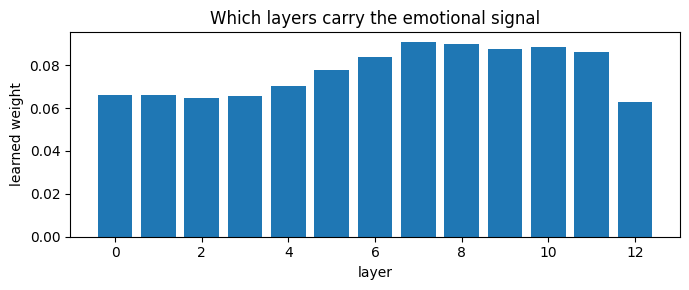

In [ ]:
import matplotlib.pyplot as plt

weights = record.get('layer_weights')
if weights:
    plt.figure(figsize=(7, 3))
    plt.bar(range(len(weights)), weights)
    plt.xlabel('layer')
    plt.ylabel('learned weight')
    plt.title('Which layers carry the emotional signal')
    plt.tight_layout()
    plt.show()
else:
    print('No layer weights — this run used last-layer pooling.')

## 11. What is saved

These are already in Drive, so they survive the session ending. **Do not put weights in the
submission zip** — the brief caps it at 5MB and says the model goes on your own drive, with
the link in the readme.

In [ ]:
for path in sorted((DRIVE_ROOT / 'checkpoints').glob('*.pt')):
    print(path.name, f'{path.stat().st_size / 1e6:.1f} MB')
for path in sorted((DRIVE_ROOT / 'results').glob('*.json')):
    print(path.name)

baseline_lora_best.pt 2.0 MB
baseline_lora_last.pt 2.0 MB
dry_run_best.pt 2.0 MB
dry_run_last.pt 2.0 MB
baseline_lora.json
dry_run.json
